## 1. Setup & Load Data
Di bagian ini, kita akan mengimpor semua library yang diperlukan dan memuat kedua dataset yang telah disiapkan pada tahap preprocessing (`dataset_garch_baseline.csv` dan `dataset_deep_learning.csv`). Kita juga akan memeriksa struktur awal dan informasi dari kedua dataset tersebut.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller

# Auto-detect BASE_DIR: Kaggle vs local execution
if os.path.exists("/kaggle/input"):
    BASE_DIR = "/kaggle/input"
    DATA_DIR = os.path.join(BASE_DIR, "data")
elif os.path.exists("../data"):
    BASE_DIR = os.path.abspath("..")
    DATA_DIR = os.path.join(BASE_DIR, "data")
else:
    BASE_DIR = os.path.abspath(".")
    DATA_DIR = os.path.join(BASE_DIR, "data")

CLEAN_DATA_DIR = os.path.join(DATA_DIR, "clean")
RAW_DATA_DIR = os.path.join(DATA_DIR, "raw")

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

# Load Datasets
df_garch = pd.read_csv(os.path.join(CLEAN_DATA_DIR, 'dataset_garch_baseline.csv'), parse_dates=['Date'])
df_dl = pd.read_csv(os.path.join(CLEAN_DATA_DIR, 'dataset_deep_learning.csv'), parse_dates=['Date'])

print("=== DATASET GARCH BASELINE ===")
display(df_garch.head())
df_garch.info()

print("
=== DATASET DEEP LEARNING ===")
display(df_dl.head())
df_dl.info()


=== DATASET GARCH BASELINE ===


,Date,ret_saham_nvda,ret_saham_msft,ret_saham_tsla,ret_saham_googl,ret_saham_meta,ret_crypto_btc_usd,ret_crypto_eth_usd,ret_crypto_btc_idr_indodax,ret_konteks_ihsg,ret_konteks_vix,ret_konteks_usdidr
0,2020-01-03,-0.016135,-0.012530,0.029203,-0.005245,-0.005305,0.050172,0.051709,0.037040,0.006327,0.117159,0.014184
1,2020-01-06,0.004185,0.002582,0.019072,0.026305,0.018658,0.056166,0.072803,0.050821,-0.010502,-0.012200,0.003561
2,2020-01-07,0.012034,-0.009160,0.038067,-0.001933,0.002161,0.049527,-0.005282,0.031354,0.003501,-0.004342,-0.000561
3,2020-01-08,0.001874,0.015803,0.048033,0.007093,0.010087,-0.010322,-0.016053,0.019766,-0.008582,-0.024965,-0.004265
4,2020-01-09,0.010923,0.012415,-0.022189,0.010443,0.014210,-0.025165,-0.016265,-0.030456,0.007809,-0.070056,0.001420


<class 'pandas.DataFrame'>
RangeIndex: 1556 entries, 0 to 1555
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Date                        1556 non-null   datetime64[us]
 1   ret_saham_nvda              1556 non-null   float64       
 2   ret_saham_msft              1556 non-null   float64       
 3   ret_saham_tsla              1556 non-null   float64       
 4   ret_saham_googl             1556 non-null   float64       
 5   ret_saham_meta              1556 non-null   float64       
 6   ret_crypto_btc_usd          1556 non-null   float64       
 7   ret_crypto_eth_usd          1556 non-null   float64       
 8   ret_crypto_btc_idr_indodax  1556 non-null   float64       
 9   ret_konteks_ihsg            1556 non-null   float64       
 10  ret_konteks_vix             1556 non-null   float64       
 11  ret_konteks_usdidr          1556 non-null   float64       
dtypes: 

,Date,crypto_btc_usd_weekend_return,ret_crypto_btc_usd,crypto_eth_usd_weekend_return,ret_crypto_eth_usd,crypto_btc_idr_indodax_weekend_return,ret_crypto_btc_idr_indodax,ret_saham_nvda,ret_saham_msft,ret_saham_tsla,ret_saham_googl,ret_saham_meta,ret_konteks_vix,ret_konteks_usdidr,is_ihsg_holiday,ret_konteks_ihsg,gap_days,day_of_week,is_monday
0,2020-01-03,0.000000,0.050172,0.000000,0.051709,0.000000,0.037040,-0.016135,-0.012530,0.029203,-0.005245,-0.005305,0.117159,0.014184,0,0.006327,1,4,0
1,2020-01-06,0.009004,0.047161,0.015568,0.057235,0.000029,0.050792,0.004185,0.002582,0.019072,0.026305,0.018658,-0.012200,0.003561,0,-0.010502,3,0,1
2,2020-01-07,0.000000,0.049527,0.000000,-0.005282,0.000000,0.031354,0.012034,-0.009160,0.038067,-0.001933,0.002161,-0.004342,-0.000561,0,0.003501,1,1,0
3,2020-01-08,0.000000,-0.010322,0.000000,-0.016053,0.000000,0.019766,0.001874,0.015803,0.048033,0.007093,0.010087,-0.024965,-0.004265,0,-0.008582,1,2,0
4,2020-01-09,0.000000,-0.025165,0.000000,-0.016265,0.000000,-0.030456,0.010923,0.012415,-0.022189,0.010443,0.014210,-0.070056,0.001420,0,0.007809,1,3,0


<class 'pandas.DataFrame'>
RangeIndex: 1677 entries, 0 to 1676
Data columns (total 19 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   Date                                   1677 non-null   datetime64[us]
 1   crypto_btc_usd_weekend_return          1677 non-null   float64       
 2   ret_crypto_btc_usd                     1677 non-null   float64       
 3   crypto_eth_usd_weekend_return          1677 non-null   float64       
 4   ret_crypto_eth_usd                     1677 non-null   float64       
 5   crypto_btc_idr_indodax_weekend_return  1677 non-null   float64       
 6   ret_crypto_btc_idr_indodax             1677 non-null   float64       
 7   ret_saham_nvda                         1677 non-null   float64       
 8   ret_saham_msft                         1677 non-null   float64       
 9   ret_saham_tsla                         1677 non-null   float64       
 10 

## 2. Statistik Deskriptif
Bagian ini menampilkan statistik deskriptif dasar (mean, standar deviasi, nilai minimum, nilai maksimum, skewness, dan kurtosis) untuk setiap kolom return pada dataset baseline. Ini membantu kita memahami distribusi sentral dan dispersi dari masing-masing instrumen.

In [2]:
# Kita gunakan df_garch karena berisi log-return reguler yang selaras
return_cols = [col for col in df_garch.columns if col.startswith('ret_')]

stats_list = []
for col in return_cols:
    data = df_garch[col].dropna()
    stats_list.append({
        'Instrumen': col.replace('ret_', ''),
        'Mean': data.mean(),
        'Std Dev': data.std(),
        'Min': data.min(),
        'Max': data.max(),
        'Skewness': data.skew(),
        'Kurtosis': data.kurtosis()
    })

df_stats = pd.DataFrame(stats_list).set_index('Instrumen')
display(df_stats)

,Mean,Std Dev,Min,Max,Skewness,Kurtosis
Instrumen,,,,,,
saham_nvda,0.002348,0.033512,-0.203979,0.218088,0.157084,4.478859
saham_msft,0.000767,0.019989,-0.159453,0.144159,-0.093649,8.411660
saham_tsla,0.001615,0.042535,-0.236518,0.204491,-0.134184,3.702477
saham_googl,0.001033,0.021217,-0.123685,0.097348,-0.136581,4.000388
saham_meta,0.000699,0.028840,-0.306391,0.209308,-1.013646,19.409992
crypto_btc_usd,0.001564,0.040381,-0.464730,0.191527,-1.371836,16.405174
crypto_eth_usd,0.001902,0.053841,-0.550732,0.324971,-0.951215,11.971048
crypto_btc_idr_indodax,0.001712,0.036714,-0.416299,0.183797,-1.279509,16.700645
konteks_ihsg,0.000035,0.011883,-0.082318,0.097042,-0.429953,8.947683


## 3. Uji Stasioneritas (Augmented Dickey-Fuller Test)
Model ekonometrika seperti GARCH dan VAR mensyaratkan agar data time series bersifat stasioner. Bagian ini menjalankan uji Augmented Dickey-Fuller (ADF) pada setiap kolom return untuk memverifikasi asumsi stasioneritas. Hipotesis nol (H0) dari uji ADF adalah data tidak stasioner.

In [3]:
adf_results = []
alpha = 0.05

for col in return_cols:
    data = df_garch[col].dropna()
    result = adfuller(data)
    stat = result[0]
    p_value = result[1]
    is_stationary = "Ya" if p_value < alpha else "Tidak"
    
    adf_results.append({
        'Instrumen': col.replace('ret_', ''),
        'ADF Statistic': stat,
        'p-value': p_value,
        'Stasioner (alpha=0.05)?': is_stationary
    })

df_adf = pd.DataFrame(adf_results).set_index('Instrumen')
display(df_adf)

,ADF Statistic,p-value,Stasioner (alpha=0.05)?
Instrumen,,,
saham_nvda,-13.759196,1.016035e-25,Ya
saham_msft,-45.346160,0.000000e+00,Ya
saham_tsla,-21.536589,0.000000e+00,Ya
saham_googl,-41.876837,0.000000e+00,Ya
saham_meta,-42.064528,0.000000e+00,Ya
crypto_btc_usd,-17.523000,4.275747e-30,Ya
crypto_eth_usd,-18.268252,2.322758e-30,Ya
crypto_btc_idr_indodax,-21.020992,0.000000e+00,Ya
konteks_ihsg,-15.563708,2.027326e-28,Ya


**Interpretasi Hasil ADF Test:**
Tabel di atas menunjukkan nilai statistik ADF dan p-value untuk setiap instrumen. Jika `p-value < 0.05`, kita menolak Hipotesis Nol (H0) yang berarti data time-series return bersifat **stasioner**. Hal ini krusial untuk pemodelan volatilitas dan model prediktif berbasis time series agar tidak terjadi *spurious regression* (regresi palsu).

## 4. Visualisasi Harga & Return
Bagian ini memvisualisasikan data runtun waktu (time series) untuk harga penutupan yang disesuaikan (Adj Close) dan log-return harian dari setiap instrumen. Harga dimuat dari data mentah karena dataset baseline difokuskan pada log-return.

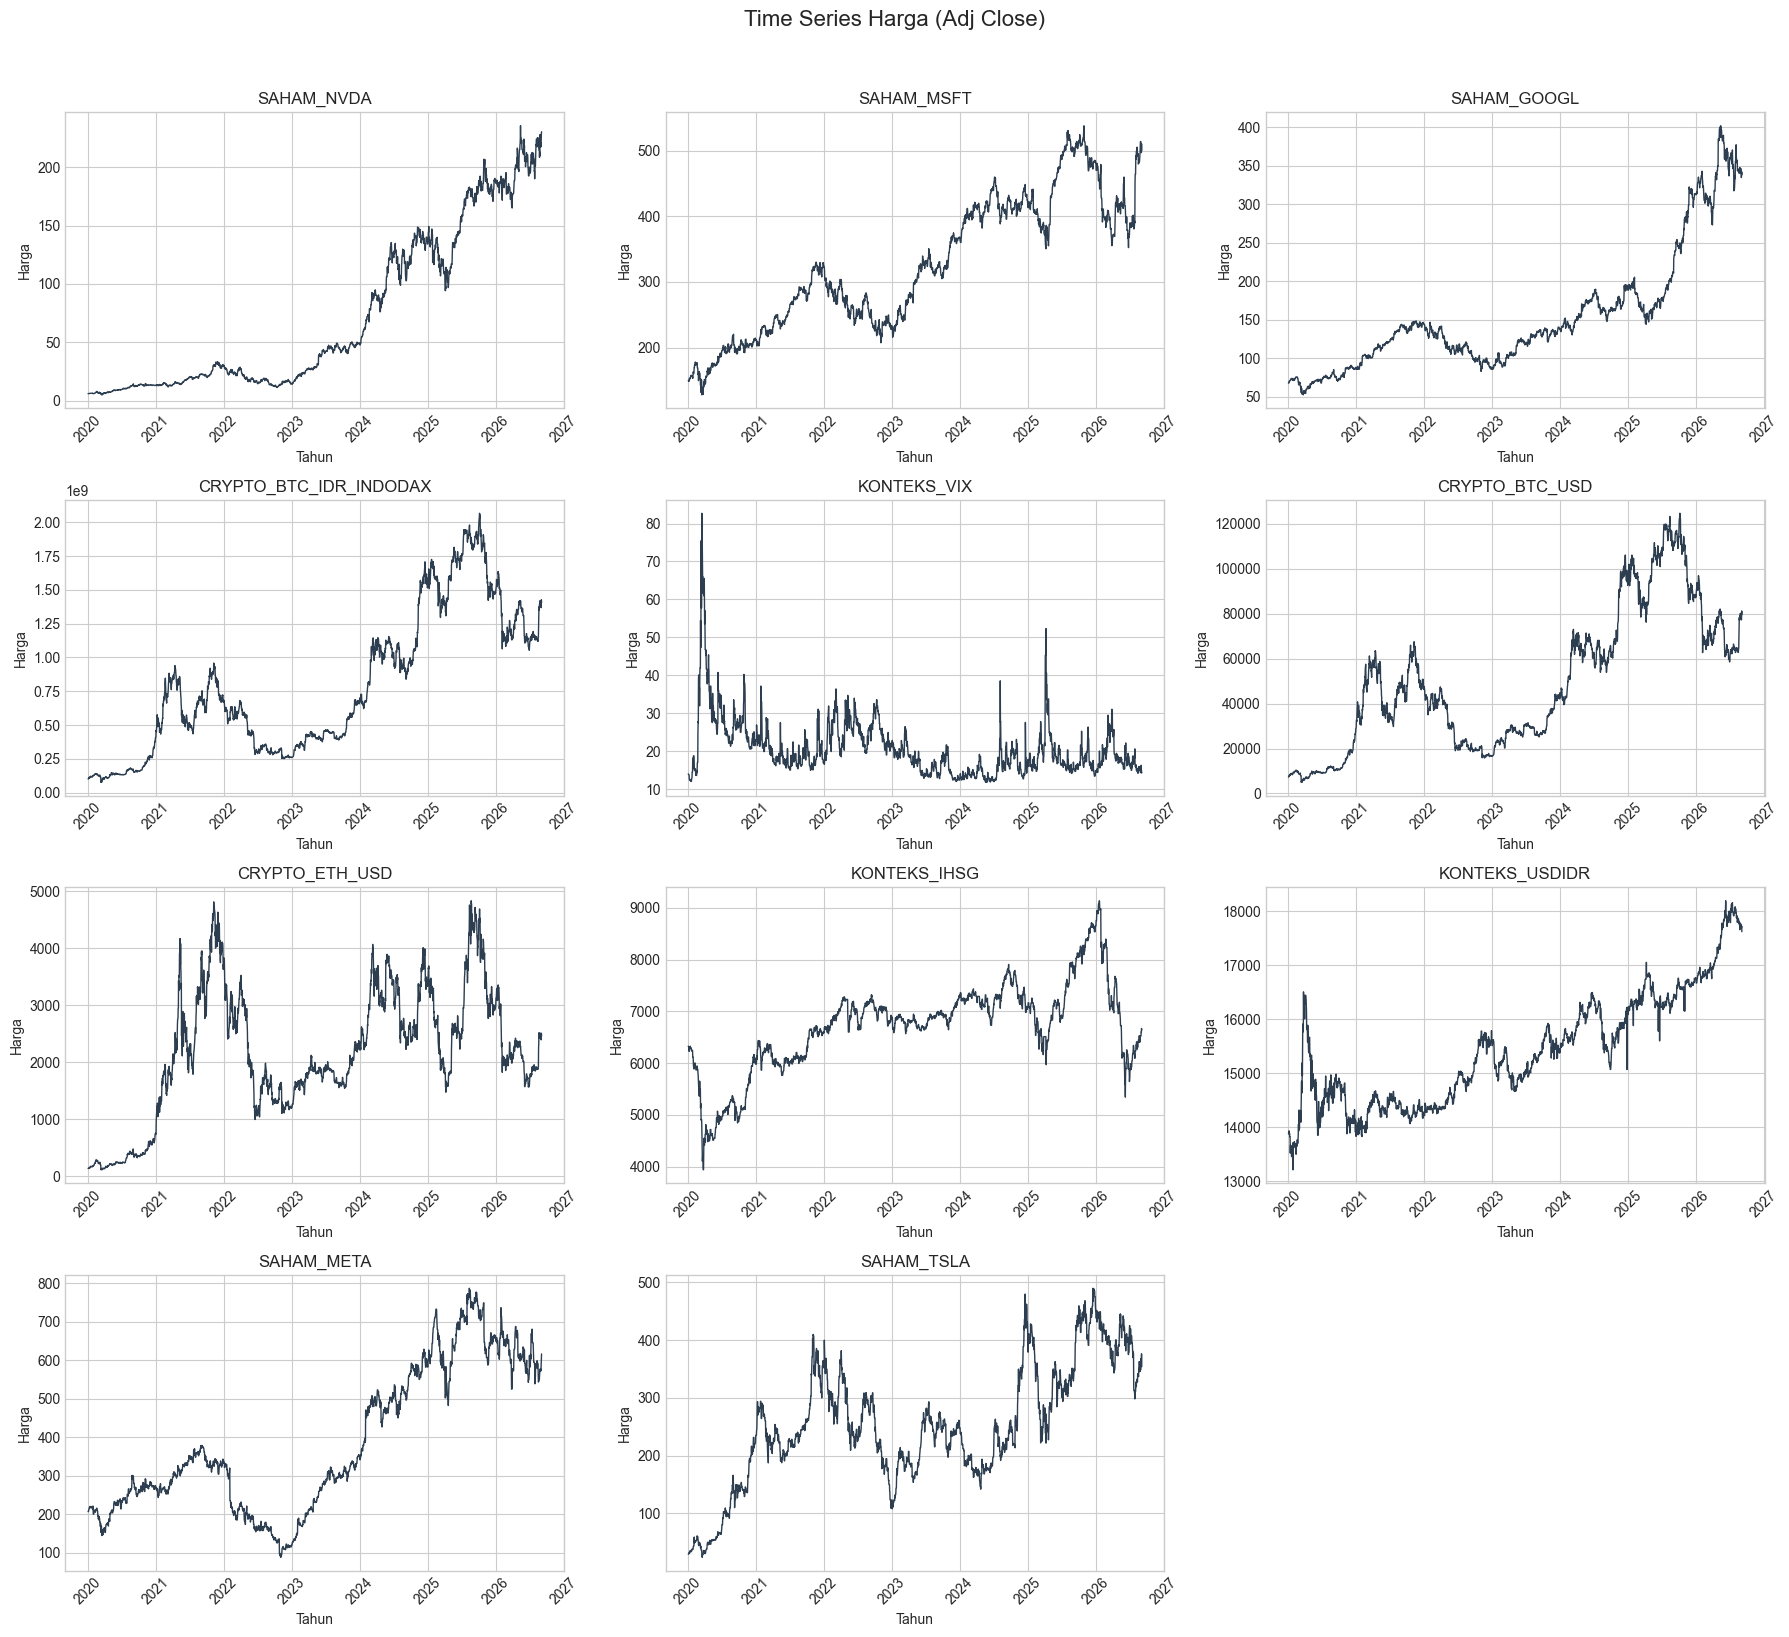

In [4]:
# Load raw data for prices
import glob

raw_files = glob.glob(os.path.join(RAW_DATA_DIR, '*.csv'))
prices = pd.DataFrame()

for file in raw_files:
    instrument_name = os.path.basename(file).replace('.csv', '')
    df_raw = pd.read_csv(file, parse_dates=['Date'])
    
    if 'Adj Close' in df_raw.columns:
        price_col = df_raw[['Date', 'Adj Close']].copy()
    else:
        price_col = df_raw[['Date', 'Close']].copy()
        price_col.rename(columns={'Close': 'Adj Close'}, inplace=True)
        
    price_col.rename(columns={'Adj Close': f'price_{instrument_name}'}, inplace=True)
    price_col.set_index('Date', inplace=True)
    
    if prices.empty:
        prices = price_col
    else:
        prices = prices.join(price_col, how='outer')

# Interpolate missing values for plotting visually continuous lines
prices.sort_index(inplace=True)
prices = prices.loc[df_garch['Date'].min():df_garch['Date'].max()]
prices.ffill(inplace=True)

# Plotting Prices
price_cols = [col for col in prices.columns if 'price_' in col]
n_cols = 3
n_rows = int(np.ceil(len(price_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
fig.suptitle('Time Series Harga (Adj Close)', fontsize=16, y=1.02)
axes = axes.flatten()

for i, col in enumerate(price_cols):
    axes[i].plot(prices.index, prices[col], color='#2c3e50', linewidth=1)
    axes[i].set_title(col.replace('price_', '').upper())
    axes[i].set_xlabel('Tahun')
    axes[i].set_ylabel('Harga')
    axes[i].tick_params(axis='x', rotation=45)

# Hide empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
    
plt.tight_layout()
plt.show()

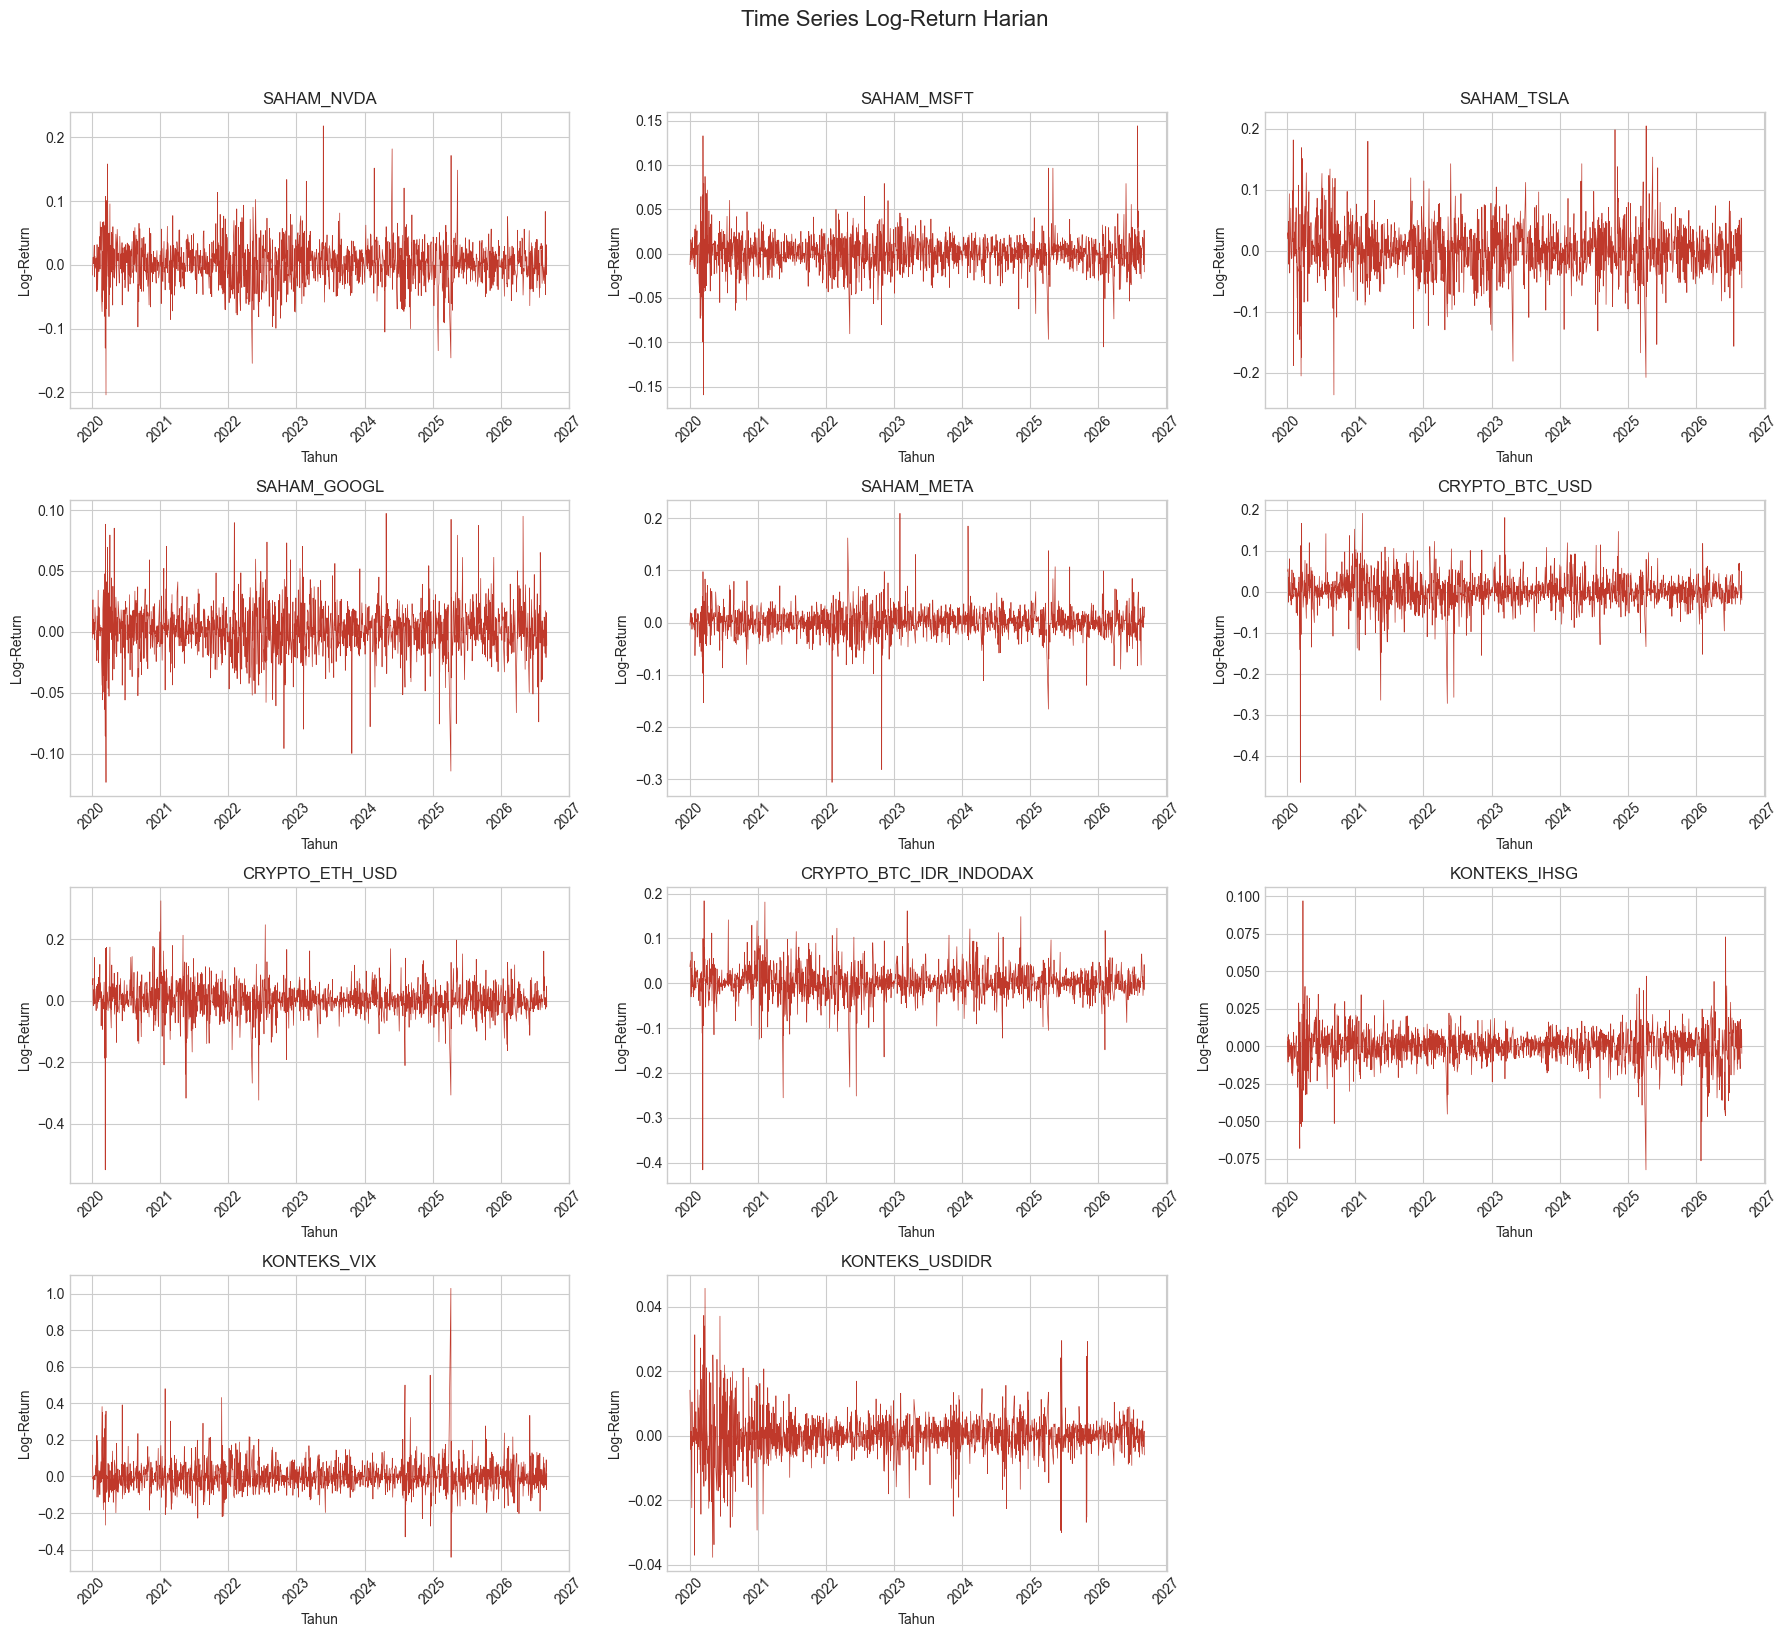

In [5]:
# Plotting Returns
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
fig.suptitle('Time Series Log-Return Harian', fontsize=16, y=1.02)
axes = axes.flatten()

for i, col in enumerate(return_cols):
    axes[i].plot(df_garch['Date'], df_garch[col], color='#c0392b', linewidth=0.5)
    axes[i].set_title(col.replace('ret_', '').upper())
    axes[i].set_xlabel('Tahun')
    axes[i].set_ylabel('Log-Return')
    axes[i].tick_params(axis='x', rotation=45)

# Hide empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
    
plt.tight_layout()
plt.show()

## 5. Distribusi Return (Fat Tails Check)
Ciri khas data finansial, khususnya kripto dan saham teknologi, adalah adanya *fat tails* (ekor tebal), di mana kejadian ekstrem lebih sering terjadi dibandingkan asumsi distribusi normal. Kita akan memeriksa ini dengan Histogram + KDE (Kernel Density Estimation) dan QQ-Plots.

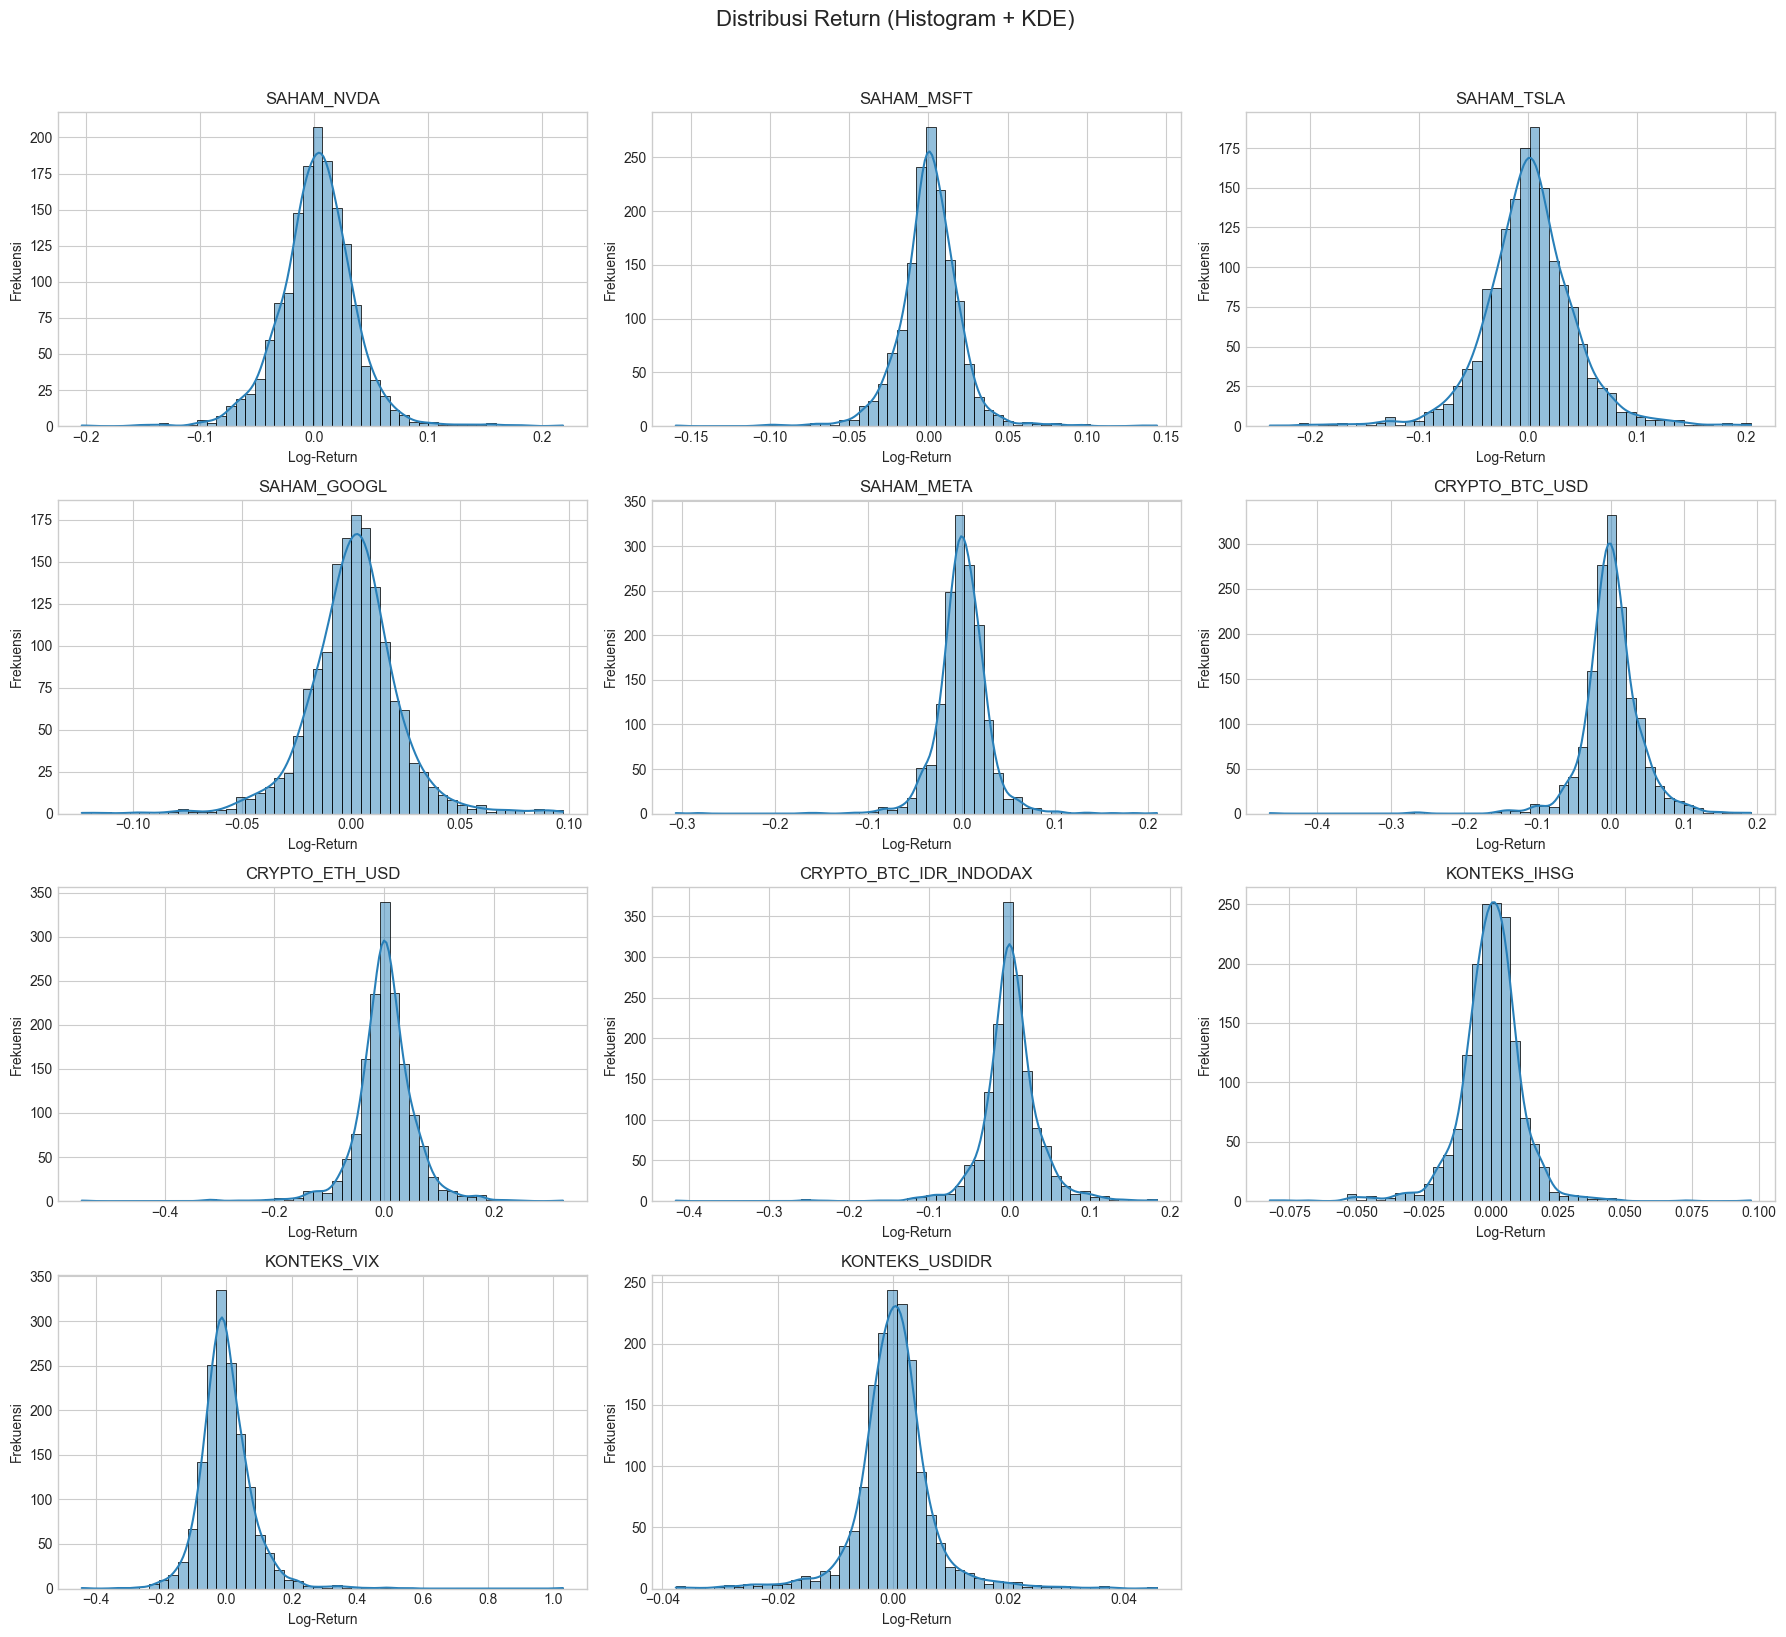

In [6]:
# Histogram + KDE
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
fig.suptitle('Distribusi Return (Histogram + KDE)', fontsize=16, y=1.02)
axes = axes.flatten()

for i, col in enumerate(return_cols):
    sns.histplot(df_garch[col].dropna(), bins=50, kde=True, ax=axes[i], color='#2980b9')
    axes[i].set_title(col.replace('ret_', '').upper())
    axes[i].set_xlabel('Log-Return')
    axes[i].set_ylabel('Frekuensi')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
    
plt.tight_layout()
plt.show()

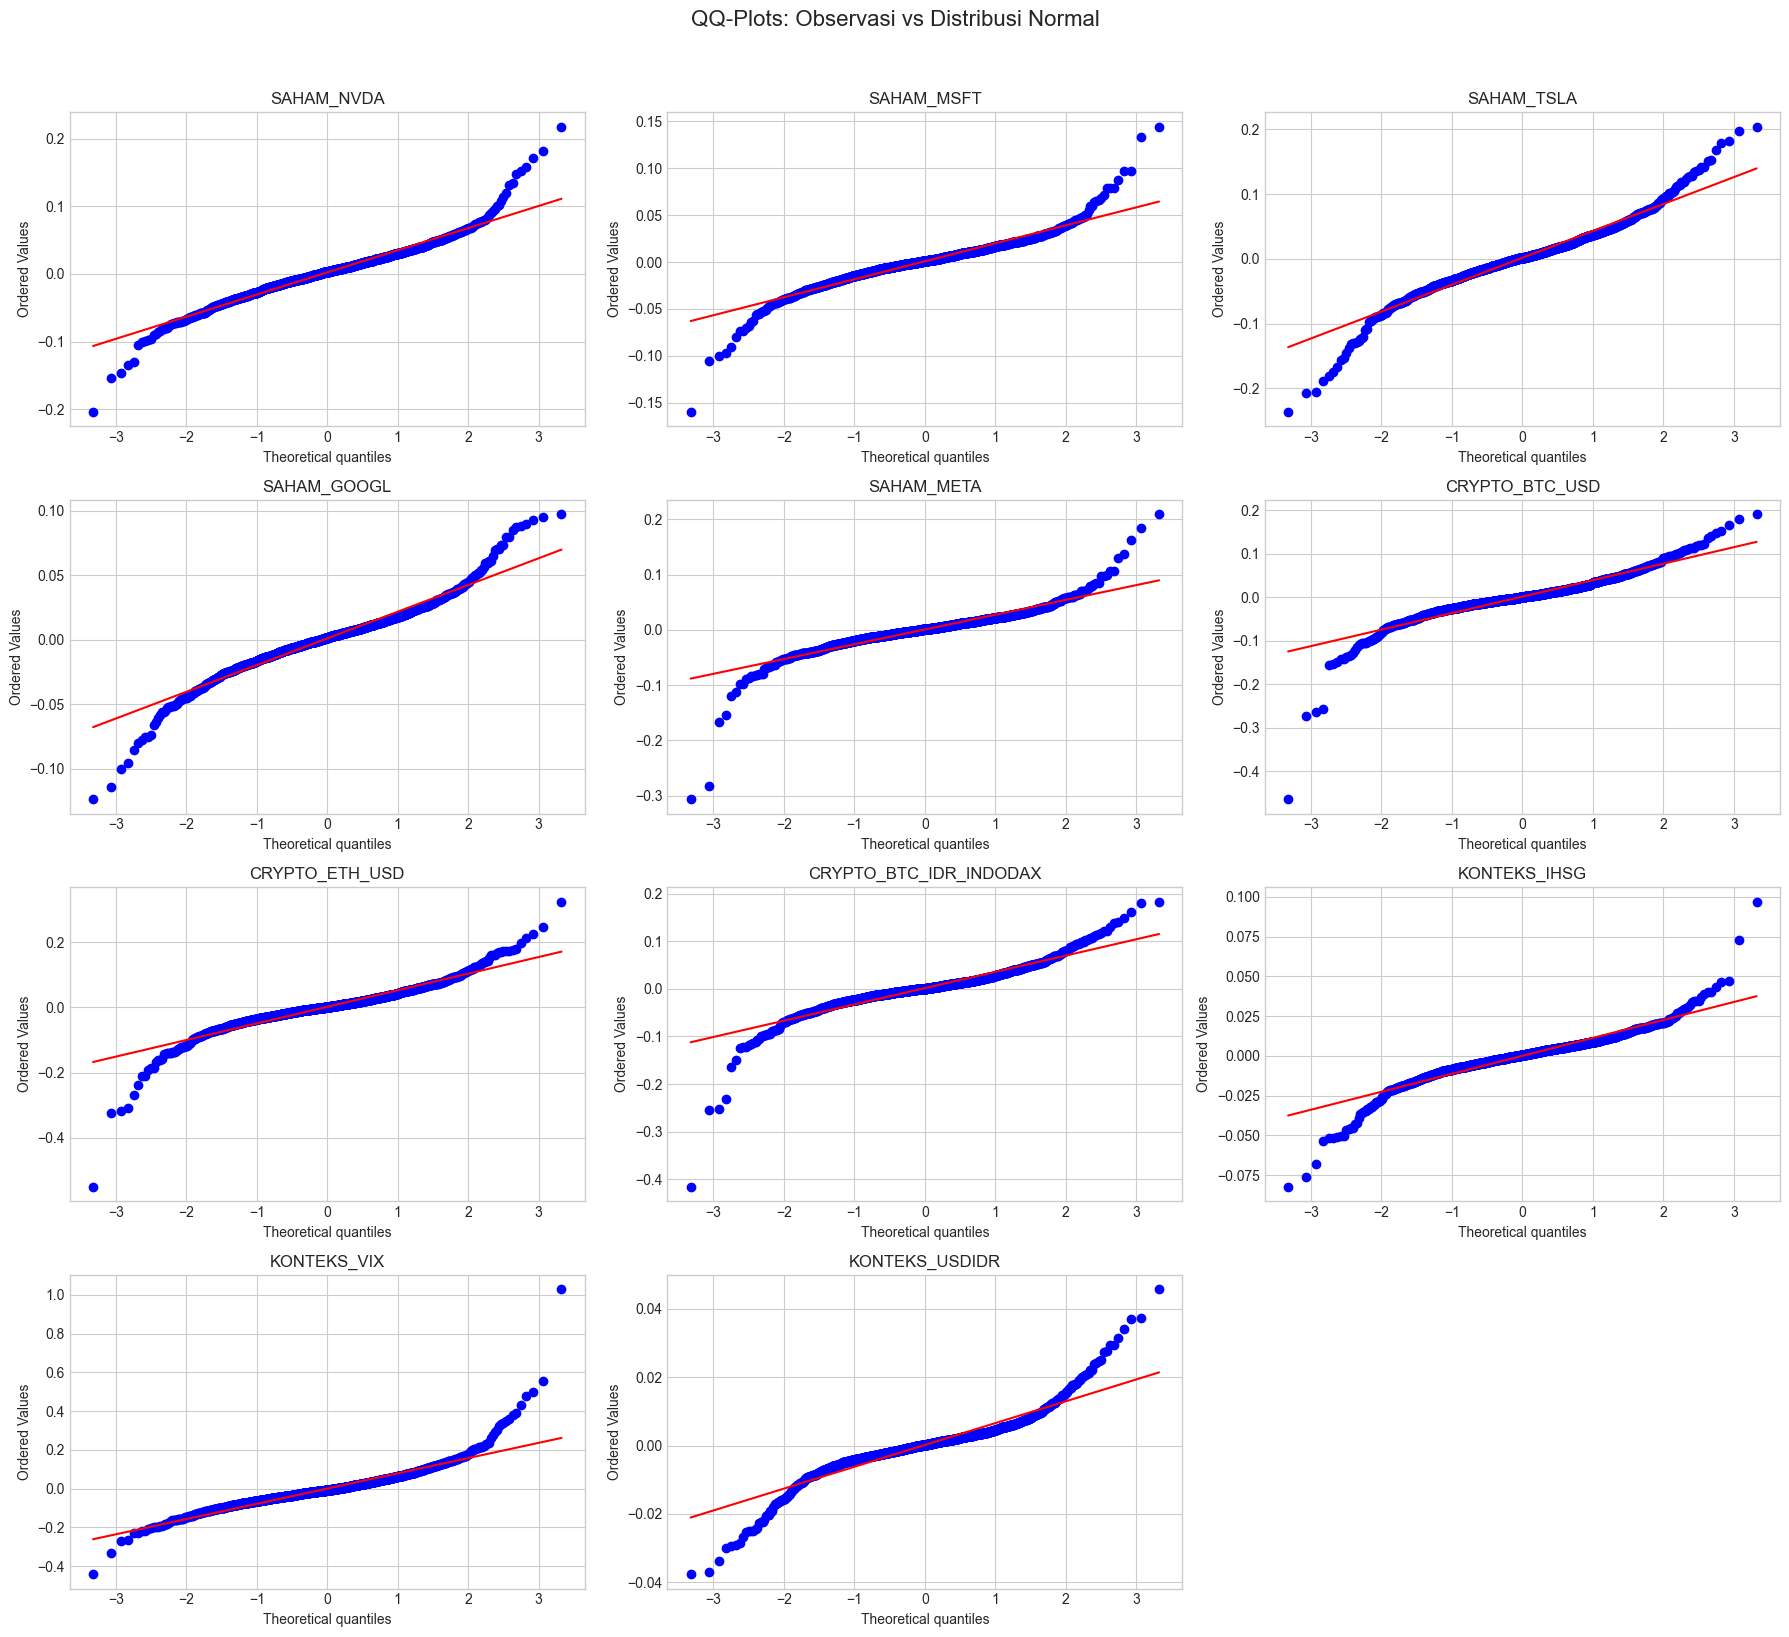

In [7]:
# QQ-Plots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
fig.suptitle('QQ-Plots: Observasi vs Distribusi Normal', fontsize=16, y=1.02)
axes = axes.flatten()

for i, col in enumerate(return_cols):
    stats.probplot(df_garch[col].dropna(), dist="norm", plot=axes[i])
    axes[i].set_title(col.replace('ret_', '').upper())

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
    
plt.tight_layout()
plt.show()

**Interpretasi QQ-Plot & Distribusi (Fat-Tail):**
Pada QQ-Plot, titik-titik data yang menyimpang dari garis lurus merah di bagian ujung kiri dan kanan mengindikasikan adanya *fat-tails*. Instrumen kripto (seperti BTC dan ETH) dan beberapa saham AI sangat mungkin menunjukkan ekor tebal yang signifikan, yang mengindikasikan bahwa return ekstrem lebih sering terjadi dibandingkan distribusi normal standar.

## 6. Correlation Heatmap
Analisis korelasi ini bertujuan untuk mengidentifikasi tingkat hubungan linier antar instrumen berdasarkan log-return mereka. Korelasi tinggi dapat menjadi indikasi awal adanya keterhubungan pasar (spillover) yang akan dimodelkan lebih dalam nanti.

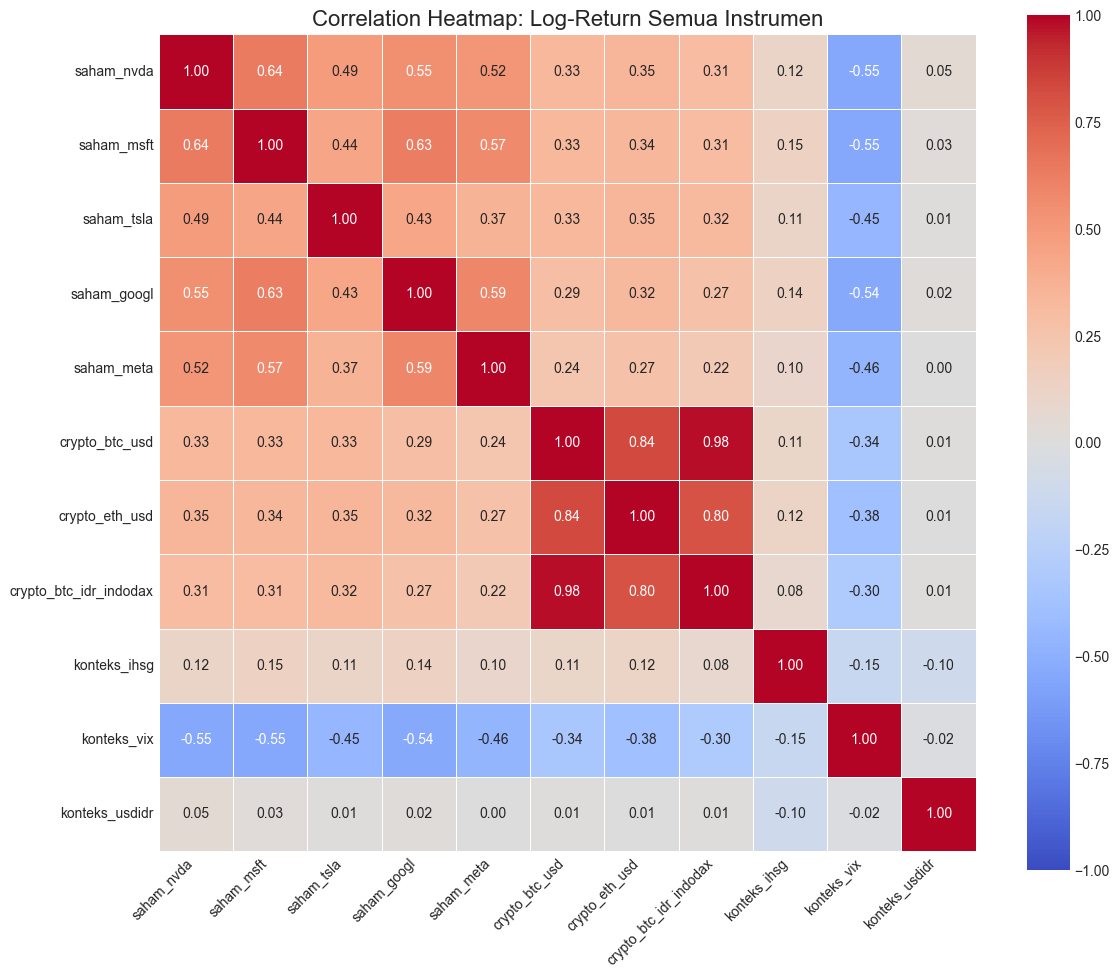

In [8]:
# Hitung korelasi antar return
corr_matrix = df_garch[return_cols].corr()

# Buat label lebih rapi
clean_labels = [c.replace('ret_', '') for c in return_cols]
corr_matrix.columns = clean_labels
corr_matrix.index = clean_labels

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=.5)
plt.title("Correlation Heatmap: Log-Return Semua Instrumen", fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretasi Heatmap:**
Nilai korelasi mendekati 1 menunjukkan hubungan positif kuat (kedua aset sering bergerak searah), nilai mendekati -1 menunjukkan hubungan negatif kuat (bergerak berlawanan), dan nilai mendekati 0 menunjukkan tidak ada hubungan linier. Kripto vs Kripto kemungkinan memiliki korelasi tinggi, sedangkan Kripto vs Saham dapat bervariasi.

## 7. Rolling Volatility
Untuk mengamati dinamika volatilitas dari waktu ke waktu, kita memplot standar deviasi bergulir (rolling std) dalam jendela 30 hari perdagangan. Kita memilih perwakilan: BTC-USD, NVDA, dan BTC-IDR Indodax.

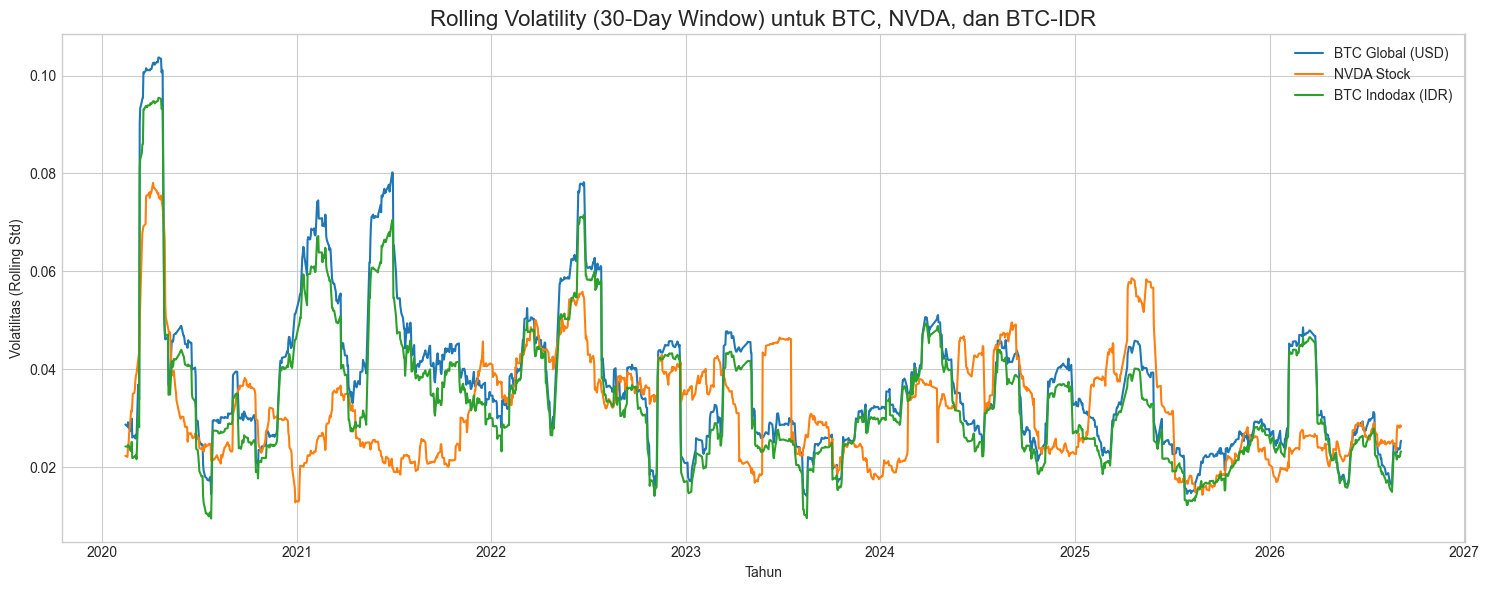

In [9]:
# Hitung rolling std 30-hari
window = 30
vol_cols = ['ret_crypto_btc_usd', 'ret_saham_nvda', 'ret_crypto_btc_idr_indodax']
labels = ['BTC Global (USD)', 'NVDA Stock', 'BTC Indodax (IDR)']

plt.figure(figsize=(15, 6))
for col, label in zip(vol_cols, labels):
    rolling_vol = df_garch[col].rolling(window=window).std()
    plt.plot(df_garch['Date'], rolling_vol, label=label, linewidth=1.5)

plt.title('Rolling Volatility (30-Day Window) untuk BTC, NVDA, dan BTC-IDR', fontsize=16)
plt.xlabel('Tahun')
plt.ylabel('Volatilitas (Rolling Std)')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretasi Dinamika Volatilitas:**
Terlihat adanya lonjakan volatilitas (*volatility clustering*) pada beberapa periode tertentu:
- *Pertengahan 2021*: Volatilitas tinggi di kripto.
- *Mei 2022*: Lonjakan sejalan dengan runtuhnya ekosistem Terra/LUNA.
- *November 2022*: Lonjakan besar pada kripto berkaitan dengan krisis FTX.
Ini membuktikan fenomena heteroskedastisitas (volatilitas yang berubah seiring waktu) yang mana menjadi alasan penggunaan model GARCH maupun Neural Network yang sensitif terhadap volatilitas.

## 8. Ringkasan Insight
Berdasarkan serangkaian proses Exploratory Data Analysis (EDA) di atas, kita dapat menyimpulkan:
1. **Volatilitas Ekstrem**: Instrumen kripto memiliki fluktuasi (*spread* antara nilai min dan max serta standar deviasi) yang relatif lebih besar dibanding sebagian besar saham dan variabel makro. Namun, saham-saham spesifik AI seperti NVDA dan TSLA juga menunjukkan profil risiko yang cukup tinggi.
2. **Stasioneritas Terpenuhi**: Berdasarkan uji statistik Augmented Dickey-Fuller (ADF), semua variabel return memiliki p-value signifikan (< 0.05). Dengan demikian, data runtun waktu yang telah didiferensiasi ke dalam wujud log-return ini *sudah stasioner* dan aman digunakan untuk modeling GARCH, VAR, maupun Deep Learning tanpa risiko *spurious regression*.
3. **Karakteristik Distribusi Ekor Tebal (Fat Tails)**: Analisis Histogram, KDE, dan QQ-plot memperlihatkan bahwa return dari instrumen-instrumen ini melenceng dari kurva Normal, dengan penumpukan observasi yang substansial pada area ekstrem ujung kurva. Ini mengindikasikan besarnya risiko lompatan harga (jumps).
4. **Indikasi Spillover (Korelasi & Volatilitas Bersama)**: Heatmap menunjukkan korelasi lintas pasar antara beberapa saham teknologi besar dan kripto. Selain itu, *volatility clustering* yang tampak pada rolling plot mengindikasikan guncangan di satu pasar berpotensi menular ke pasar lain pada jendela krisis (seperti akhir 2022).

## 9. ARCH-LM Test (Uji Formal Volatility Clustering)
Uji ARCH-LM (Engle's Test) digunakan untuk mendeteksi keberadaan efek Autoregressive Conditional Heteroskedasticity (ARCH) pada residual return. Jika terdapat efek ARCH yang signifikan, hal ini memberikan justifikasi formal dan absolut bahwa pemodelan menggunakan keluarga GARCH (Generalized ARCH) sangat tepat untuk menangkap *volatility clustering*.

In [10]:
from statsmodels.stats.diagnostic import het_arch

arch_results = []
alpha = 0.05

for col in return_cols:
    data = df_garch[col].dropna()
    # Menggunakan demeaned returns sebagai proxy residual sederhana
    residuals = data - data.mean() 
    
    # Run ARCH-LM test dengan lag default
    lm_stat, p_value, f_stat, f_pvalue = het_arch(residuals)
    
    is_arch_effect = "Ya" if p_value < alpha else "Tidak"
    
    arch_results.append({
        'Instrumen': col.replace('ret_', ''),
        'LM Statistic': lm_stat,
        'p-value': p_value,
        'Efek ARCH (alpha=0.05)?': is_arch_effect
    })

df_arch = pd.DataFrame(arch_results).set_index('Instrumen')
display(df_arch)

,LM Statistic,p-value,Efek ARCH (alpha=0.05)?
Instrumen,,,
saham_nvda,76.966102,1.968707e-12,Ya
saham_msft,248.523870,1.109073e-47,Ya
saham_tsla,71.987258,1.829921e-11,Ya
saham_googl,83.252476,1.153265e-13,Ya
saham_meta,8.514632,5.787000e-01,Tidak
crypto_btc_usd,26.561063,3.054543e-03,Ya
crypto_eth_usd,42.118945,7.141913e-06,Ya
crypto_btc_idr_indodax,33.966516,1.871257e-04,Ya
konteks_ihsg,235.385890,6.372045e-45,Ya


**Interpretasi Hasil ARCH-LM Test:**
Tabel di atas menunjukkan justifikasi formal dari pemilihan model penelitian. Hasil `p-value < 0.05` menolak Hipotesis Nol (H0), yang menegaskan bahwa varians (volatilitas) dari instrumen tidak konstan (heteroskedastik) dan saling bergantung dari waktu ke waktu (*clustering*). Ini membuktikan secara statistik bahwa pemodelan GARCH adalah pendekatan yang tepat.

## 10. Korelasi Volatilitas
Pada section 6, kita melihat korelasi dari *return* mentah (perubahan arah harga). Sekarang kita menggunakan proksi volatilitas sederhana yaitu pengkuadratan return harian (*squared returns*). Ini memungkinkan kita mendeteksi *volatility spillover* awal: apakah ketika satu pasar mengalami guncangan ekstrem (tanpa peduli arah naik/turun), pasar lain juga ikut berguncang?

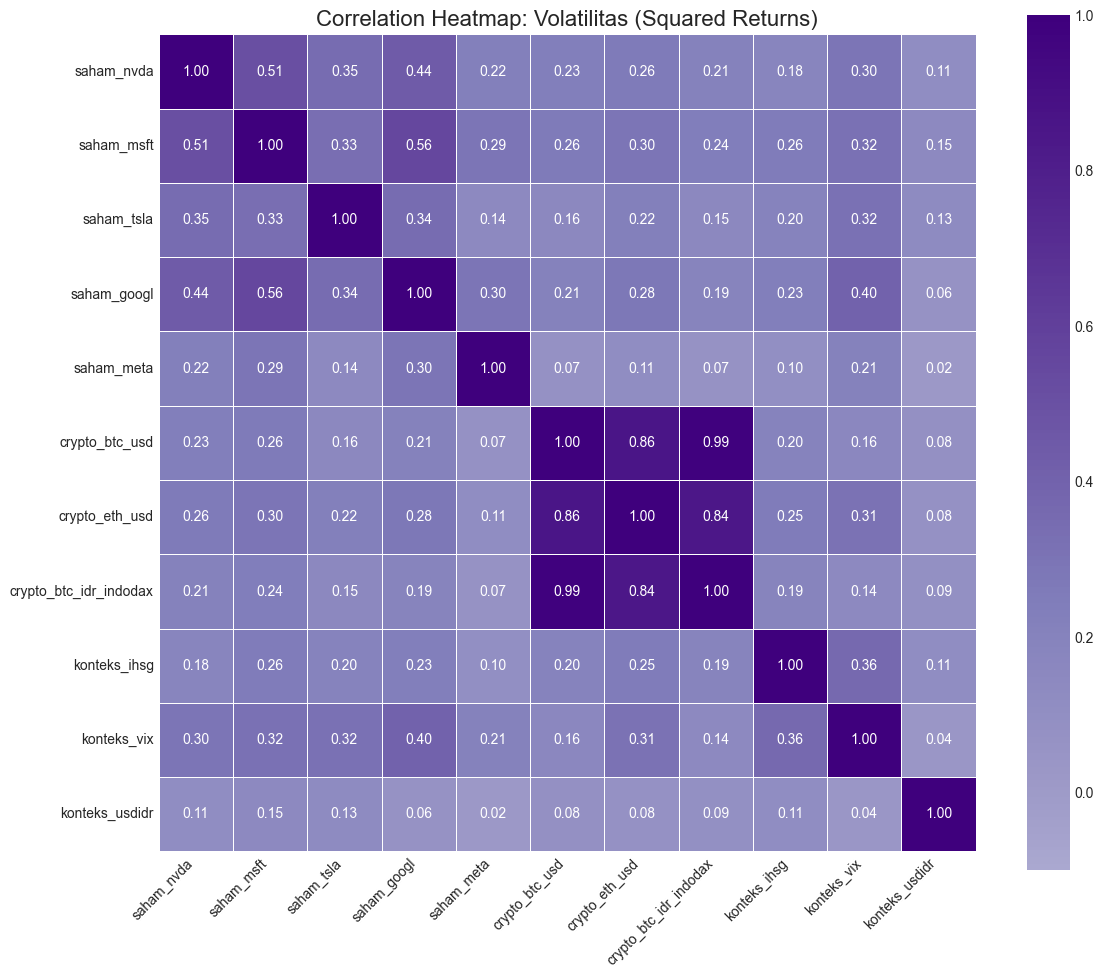

=== 10 PASANGAN DENGAN KORELASI VOLATILITAS TERTINGGI ===
crypto_btc_idr_indodax  crypto_btc_usd    0.991179
crypto_eth_usd          crypto_btc_usd    0.863718
crypto_btc_idr_indodax  crypto_eth_usd    0.842856
saham_googl             saham_msft        0.558280
saham_msft              saham_nvda        0.509437
saham_googl             saham_nvda        0.443974
konteks_vix             saham_googl       0.399837
                        konteks_ihsg      0.362374
saham_tsla              saham_nvda        0.346398
saham_googl             saham_tsla        0.343634
dtype: float64


In [11]:
# Menghitung proxy volatilitas harian (squared returns)
df_vol = df_garch[return_cols] ** 2

# Menghitung korelasi volatilitas
corr_vol = df_vol.corr()

# Buat label lebih rapi
clean_labels = [c.replace('ret_', '') for c in return_cols]
corr_vol.columns = clean_labels
corr_vol.index = clean_labels

# Plot Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_vol, annot=True, fmt=".2f", cmap="Purples", center=0, vmin=-0.1, vmax=1, square=True, linewidths=.5)
plt.title("Correlation Heatmap: Volatilitas (Squared Returns)", fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("=== 10 PASANGAN DENGAN KORELASI VOLATILITAS TERTINGGI ===")
# Unstack dan ambil nilai di bawah diagonal utama agar tidak duplikat
vol_unstacked = corr_vol.where(np.triu(np.ones(corr_vol.shape), k=1).astype(bool)).unstack()
top_10_vol = vol_unstacked.sort_values(ascending=False).head(10)
print(top_10_vol)

**Interpretasi Korelasi Volatilitas:**
Heatmap dan tabel peringkat di atas membandingkan transmisi murni "guncangan" (*squared returns*), bukan sekadar arah harganya. Jika peringkat pasangan Saham AI - Kripto meningkat di sini dibandingkan heatmap *return* mentah, hal itu merupakan indikasi awal yang sangat kuat mengenai keberadaan **Volatility Spillover** (meskipun harga mereka tidak bergerak searah, namun gelombang kepanikan/kegembiraannya menular secara lintas pasar).